In [1]:
import pandas as pd
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, accuracy_score

In [2]:
# === Step 1: Load CSVs ===
gt_path = "shuffled_metadata.csv"
pred_path = 'fairface_test_outputs.csv'

# Load ground truth and predictions
fairface_df = pd.read_csv(pred_path)
ground_truth_df = pd.read_csv(gt_path)
# Extract original filename from face_name_align
# e.g., 'img001_face0.png' -> 'img001.png'
# === Extract filename from FairFace predictions ===
fairface_df['filename'] = fairface_df['face_name_align'].apply(lambda x: x.split('/')[-1].split('_')[0] + '.png')


In [3]:

# === Map custom ethnicities to FairFace categories ===
ethnicity_mapping = {
    'Southern European': 'White',
    'Northern European': 'White',
    'Chinese': 'East Asian',
    'Filipino': 'Southeast Asian',
    'Indian': 'Indian',
    'Arabic': 'Middle Eastern',
    'African': 'Black',
    'Black Caribbean': 'Black',
    'Native American': 'Latino_Hispanic',
    'Hawaiian': 'Southeast Asian',
    'Southeast Asian': 'Southeast Asian',
    'Brazilian': 'Latino_Hispanic',
    'Indigenous Australian': 'Southeast Asian'
}

# Apply the mapping to ground truth
ground_truth_df['fairface_ethnicity'] = ground_truth_df['ethnicity'].map(ethnicity_mapping)

# === Merge DataFrames on filename ===
merged_df = pd.merge(fairface_df, ground_truth_df, on='filename')

# Drop rows where mapping failed
merged_df = merged_df.dropna(subset=['fairface_ethnicity'])

# === Prepare labels for evaluation ===
y_true = merged_df['fairface_ethnicity']
y_pred = merged_df['race']

In [4]:
# === Accuracy and Classification Report ===
accuracy = accuracy_score(y_true, y_pred)
print(f"\n✅ Ethnicity Classification Accuracy: {accuracy:.2f}\n")

print("📋 Classification Report:")
print(classification_report(y_true, y_pred))


✅ Ethnicity Classification Accuracy: 0.66

📋 Classification Report:
                 precision    recall  f1-score   support

          Black       0.97      0.91      0.94        69
     East Asian       0.70      0.97      0.81       143
         Indian       0.43      1.00      0.60       104
Latino_Hispanic       0.44      0.54      0.49       148
 Middle Eastern       0.62      0.40      0.48       101
Southeast Asian       0.90      0.34      0.50       294
          White       0.90      0.90      0.90       193

       accuracy                           0.66      1052
      macro avg       0.71      0.72      0.67      1052
   weighted avg       0.74      0.66      0.65      1052



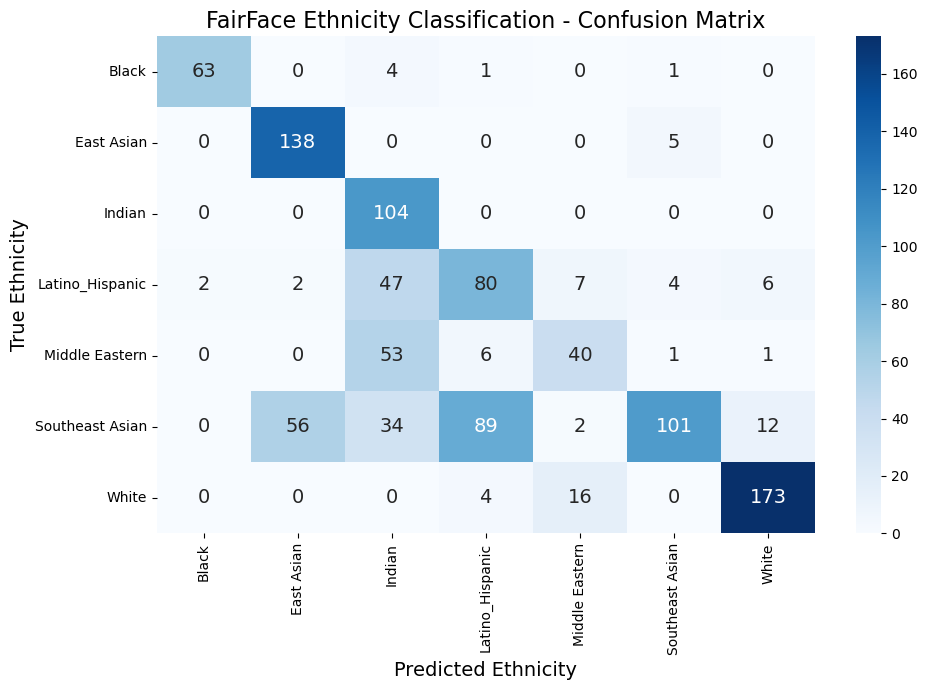

In [5]:
# === Confusion Matrix ===
labels = sorted(y_true.unique())
conf_matrix = confusion_matrix(y_true, y_pred, labels=labels)

# === Plot Confusion Matrix ===
plt.figure(figsize=(10, 7))
sns.heatmap(pd.DataFrame(conf_matrix, index=labels, columns=labels),
            annot=True, fmt='d', cmap='Blues',annot_kws={"size": 14})
plt.title("FairFace Ethnicity Classification - Confusion Matrix", fontsize=16)
plt.xlabel("Predicted Ethnicity", fontsize=14)
plt.ylabel("True Ethnicity", fontsize=14)
plt.tight_layout()
plt.show()


📊 Group-wise (Per-Ethnicity) Accuracy:
fairface_ethnicity
Indian             1.000000
East Asian         0.965035
Black              0.913043
White              0.896373
Latino_Hispanic    0.540541
Middle Eastern     0.396040
Southeast Asian    0.343537
dtype: float64


C:\Users\prisc\AppData\Local\Temp\ipykernel_27500\3203706028.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  group_accuracy = merged_df.groupby('fairface_ethnicity').apply(


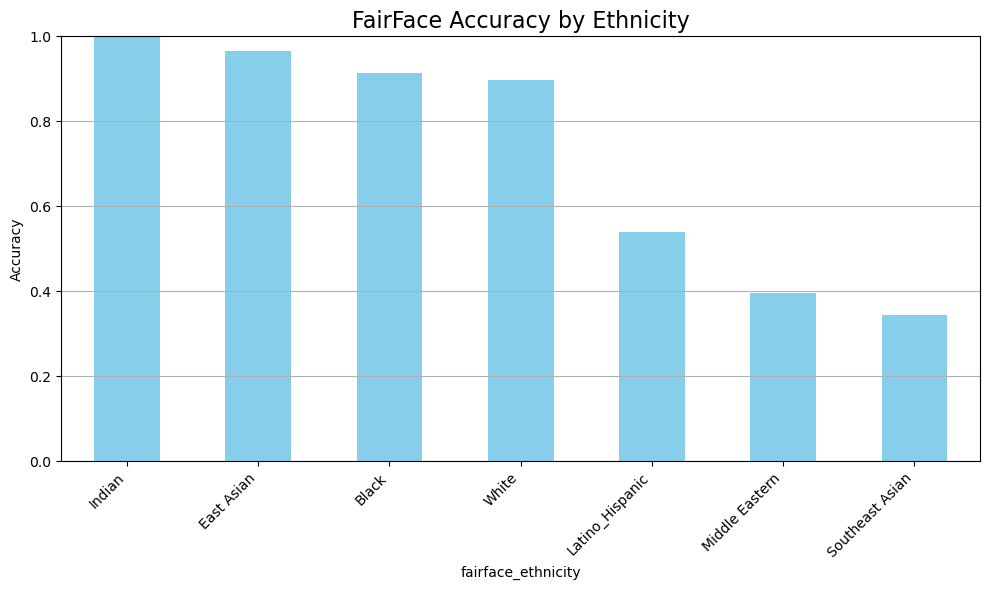

In [6]:
# === Group-wise accuracy (per-ethnicity) ===
group_accuracy = merged_df.groupby('fairface_ethnicity').apply(
    lambda x: (x['race'] == x['fairface_ethnicity']).mean()
).sort_values(ascending=False)

# Print group-wise accuracy
print("\n📊 Group-wise (Per-Ethnicity) Accuracy:")
print(group_accuracy)

# === Bar chart visualization ===
plt.figure(figsize=(10, 6))
group_accuracy.plot(kind='bar', color='skyblue')
plt.title("FairFace Accuracy by Ethnicity", fontsize=16)
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.grid(axis='y')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()
